# Mingmin

1. Response-hand alignment: early / late time-frequency maps.
2. Response-hand alignment: early / late band time courses.
3. Fast / slow: band time-course comparison (optional).
4. Fixed / random: whole-trial comparison of mean power across all 11 electrode lines.


In [1]:

# Locate the project independently of the machine and Jupyter launch directory.
import os as _path_os
import sys as _path_sys
from pathlib import Path as _ProjectPath
_path_start = _ProjectPath(__file__).resolve().parent if '__file__' in globals() else _ProjectPath.cwd()
_path_roots = ([_ProjectPath(_path_os.environ['TRAVELLING_WAVES_ROOT']).expanduser()]
               if _path_os.environ.get('TRAVELLING_WAVES_ROOT') else [])
_path_roots += [_path_start, *_path_start.parents]
_path_root = next((p for p in _path_roots if (p / 'project_locations.py').is_file()), None)
if _path_root is None:
    _path_roots = [p for mount, pattern in [('/Volumes', '*/travelling_waves'),
                    ('/media', '*/*/travelling_waves'), ('/mnt', '*/travelling_waves')]
                   for p in _ProjectPath(mount).glob(pattern)
                   if (p / 'project_locations.py').is_file()]
    if len(_path_roots) != 1:
        raise FileNotFoundError('Cannot uniquely locate travelling_waves. Set TRAVELLING_WAVES_ROOT to its directory.')
    _path_root = _path_roots[0]
_path_sys.path.insert(0, str(_path_root))
from project_locations import project_path, font_path

from pathlib import Path
import sys
import platform
import importlib
import pickle
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(project_path())
PLOT_DIR = PROJECT_ROOT / 'tw/decoding_gpu'
sys.path.insert(0, str(PLOT_DIR))
print(f'System: {platform.system()} | Project: {PROJECT_ROOT}')
from functions.tw_funcs import tw_plot_funcs as plots
plots = importlib.reload(plots)


System: Darwin | Project: /Volumes/T7/travelling_waves


In [2]:
MEASURES = ['fw', 'bw']
CORRECT_ONLY = False
N_PERMUTATIONS = 5000
SEED = 42
ALPHA = 0.05
CONTRA_LINES = ['C5', 'C4', 'C3', 'C2', 'C1']
IPSI_LINES = ['I1', 'I2', 'I3', 'I4', 'I5']
RELATIVE_LINES = ['C5', 'C4', 'C3', 'C2', 'C1', 'M', 'I1', 'I2', 'I3', 'I4', 'I5']
LINE_GROUPS = {
    'contra': [RELATIVE_LINES.index(x) for x in CONTRA_LINES],
    'ipsi': [RELATIVE_LINES.index(x) for x in IPSI_LINES],
    'mid': [5],
}
BAND_YLIMS = {'fw': (-.15, .15), 'bw': (-.15, .15)}
HAND_YLIMS = {'fw': (-.15, .15), 'bw': (-.15, .15)}
POWER_YLIMS = {'fw': (-0.5, 0.5), 'bw': (-0.5, 0.5)}
RESULT_DIR = PROJECT_ROOT / 'tw/result/mingmin_fft'
FIG_DIR = PROJECT_ROOT / 'tw/result/figs/mingmin'
MAX_RT = 1.55
RT_REMOVE = True
EXCLUDE_TIMING_ISSUE = True
EXCLUDE_BAD_EPOCH = True
EXCLUDE_SUBJECTS = set()
LINE_IDX = list(range(11))
FREQ_BANDS = [(2, 6, 'theta (2–6 Hz)'), (8, 12, 'alpha (8–12 Hz)'),
              (14, 30, 'beta (14–30 Hz)')]
PROBE_ONSET = {'early': 2.90, 'late': 5.05}
EVENTS = [(0, 'target1'), (1.15, 'target2'), (2.30, 'impulse1'),
          (2.90, 'probe1'), (4.45, 'impulse2'), (5.05, 'probe2')]
STIMULUS_BARS = [(0, .250), (1.15, .250), (2.30, .100), (2.90, .250), (4.45, .100), (5.05, .250)]
PLOT_WINDOWS = {
    'early': dict(t_start=2.75, t_stop=5.05, time_zero=2.90),
    'late': dict(t_start=4.80, t_stop=7.10, time_zero=5.05),
    'whole': dict(t_start=-1.2, t_stop=7.5, time_zero=0.0),  # Full epoch; target1 onset = 0 s.
}
# True: TF directions side by side; time-course directions stacked vertically.
# False: use separate figures (except calls explicitly setting split_measures=False).
COMBINE_MEASURES = True
PLOT_OPTIONS = dict(events=EVENTS, stimulus_bars=STIMULUS_BARS,
                    combine_measures=COMBINE_MEASURES,
                    n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA)

# TF colorbar endpoints are ± these values, in dB.
TF_LIMITS = {'fw': .30, 'bw': .30}
TF_DIFF_LIMITS = {'fw': .04, 'bw': .04}
TF_CMAP = 'coolwarm'
TF_SHOW_SIDES = False  # True also plots contra, ipsi and midline.
TF_PANEL_SIZE = (6.4, 4.8)


In [4]:
METADATA_KEYS = ('time', 'ff', 'early_response', 'late_response', 'early_acc',
                 'late_acc', 'early_rt', 'late_rt', 'is_bad_epoch', 'has_timing_issue', 'blocktype')
SESSION_PATHS = sorted(RESULT_DIR.glob('subj*_sess*.pkl'))
SESSION_PATHS = [path for path in SESSION_PATHS
                 if int(re.search(r'subj(\d+)', path.name)[1]) not in EXCLUDE_SUBJECTS]
metadata = {}

def session_metadata(path):
    if path not in metadata:
        with path.open('rb') as stream:
            data = pickle.load(stream)
        metadata[path] = {key: data[key] for key in METADATA_KEYS}
    return metadata[path]

def subject_id(path):
    return int(re.search(r'subj(\d+)', path.name)[1])

def trial_mask(data):
    keep = np.ones(len(data['early_rt']), dtype=bool)
    if RT_REMOVE:
        keep &= np.isfinite(data['early_rt']) & (data['late_rt'] <= MAX_RT)
    if EXCLUDE_BAD_EPOCH:
        keep &= ~np.asarray(data['is_bad_epoch'], bool)
    if EXCLUDE_TIMING_ISSUE:
        keep &= ~np.asarray(data['has_timing_issue'], bool)
    if CORRECT_ONLY:
        keep &= (data['early_acc'] == 1) & (data['late_acc'] == 1)
    return keep

def alignment_mask(data, alignment, rt_type):
    return data[rt_type+'_response'] == 1 if alignment == 'hand' else np.zeros(len(data['early_rt']), bool)

def condition_masks(data, rt_type, comparison, median_rt):
    keep = trial_mask(data)
    if comparison == 'fixed_random':
        block = np.char.lower(np.asarray(data['blocktype']).astype(str))
        return {'all': keep, **{name: keep & (block == name) for name in ('fixed', 'random')}}
    if comparison == 'fast_slow':
        rt = data[rt_type+'_rt']
        return {'fast': keep & (rt < median_rt), 'slow': keep & (rt > median_rt)}
    return {'all': keep}

def prepare_maps(*, alignment, rt_type=None, comparison='all', groups=LINE_GROUPS):
    if (alignment == 'hand' or comparison == 'fast_slow') and rt_type not in ('early', 'late'):
        raise ValueError('rt_type must be early or late for hand alignment or fast_slow comparison')
    # Fast/slow uses each subject's pooled-session median; ties are omitted.
    medians = {}
    if comparison == 'fast_slow':
        for subject in sorted({subject_id(path) for path in SESSION_PATHS}):
            rt = [session_metadata(path)[rt_type+'_rt'][trial_mask(session_metadata(path))]
                  for path in SESSION_PATHS if subject_id(path) == subject]
            medians[subject] = np.median(np.concatenate(rt))
    def sessions():
        for path in SESSION_PATHS:
            meta = session_metadata(path)
            subject = subject_id(path)
            with path.open('rb') as stream:
                data = pickle.load(stream)
            time = -1.2 + (np.asarray(data['time'])+125)/500
            power = plots.normalize_power(data['fwmax'], data['fwssmax'], data['bwmax'], data['bwssmax'])
            del data
            yield dict(subject=subject, session=path.stem, time=time, frequencies=np.asarray(meta['ff']), power=power, selections=condition_masks(meta, rt_type, comparison, medians.get(subject)), flip=alignment_mask(meta, alignment, rt_type), rt={key: np.asarray(meta[key]) for key in ('early_rt', 'late_rt')})
    return plots.collect_maps(sessions(), groups=groups, align=alignment != 'physical',
                              weighting='trial' if comparison == 'fast_slow' else 'session')

def rt_lines(data):
    return [(PROBE_ONSET[key]+np.mean(np.concatenate(list(data['rt'][key+'_rt'].values()))), color, key+' RT')
            for key, color in [('early', 'red'), ('late', 'green')]]

def output_dir():
    return FIG_DIR / 'no-bl'


In [6]:
rows = []
for path in SESSION_PATHS:
    data = session_metadata(path)
    n = len(data['early_rt'])
    keep = trial_mask(data)
    rows.append(dict(subject=subject_id(path), total=n, kept=int(keep.sum()),
        early_correct=int((data['early_acc']==1).sum()),
        late_correct=int((data['late_acc']==1).sum()),
        #both_correct=int(((data['early_acc']==1)&(data['late_acc']==1)).sum()),
        bad_epoch=int(np.asarray(data['is_bad_epoch'], bool).sum()),
        early_rt=data['early_rt'][keep],
        late_rt=data['late_rt'][keep]))
trial_summary = pd.DataFrame(rows).groupby('subject').agg(
    total=('total','sum'), kept=('kept','sum'), #both_correct=('both_correct','sum'),
    early_correct=('early_correct','sum'), late_correct=('late_correct','sum'),
    bad_epoch=('bad_epoch','sum'),
    early_rt_mean=('early_rt', lambda rt: np.mean(np.concatenate(rt.to_list()))),
    late_rt_mean=('late_rt', lambda rt: np.mean(np.concatenate(rt.to_list()))))
trial_summary['early_acc_mean'] = trial_summary.pop('early_correct') / trial_summary['total']
trial_summary['late_acc_mean'] = trial_summary.pop('late_correct') / trial_summary['total']
trial_summary['kept_percent'] = 100*trial_summary.kept/trial_summary.total
display(trial_summary)
print('Subjects:', trial_summary.index.tolist())


,total,kept,bad_epoch,early_rt_mean,late_rt_mean,early_acc_mean,late_acc_mean,kept_percent
subject,,,,,,,,
1,1680,1046,282,0.952628,0.822093,0.914286,0.915476,62.261905
2,1680,1035,442,1.031522,0.898498,0.739286,0.735714,61.607143
3,1680,881,601,0.820048,0.738559,0.773810,0.744048,52.440476
4,1680,1222,106,1.038433,0.793677,0.802976,0.795833,72.738095
5,1680,1139,269,1.016990,0.911018,0.788690,0.769643,67.797619
6,1680,1271,198,0.981894,0.768367,0.788690,0.769048,75.654762
7,1680,838,613,1.065314,0.897947,0.701190,0.699405,49.880952
8,1679,771,645,0.940299,0.823725,0.842168,0.807624,45.920191
9,1680,348,1140,0.827795,0.759116,0.880357,0.858333,20.714286


Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]


In [7]:
# Group-level behavioral summary: each subject contributes equally.
# Preserve the trial definitions used in trial_summary above.
subject_behavior = pd.DataFrame({
    'Early RT (s)': trial_summary['early_rt_mean'],
    'Late RT (s)': trial_summary['late_rt_mean'],
    'Early accuracy (%)': 100 * trial_summary['early_acc_mean'],
    'Late accuracy (%)': 100 * trial_summary['late_acc_mean'],
})
group_summary = subject_behavior.agg(['count', 'mean', 'std', 'sem']).T
group_summary = group_summary.rename(columns={'count': 'n_subjects', 'std': 'sd'})
group_summary['n_subjects'] = group_summary['n_subjects'].astype(int)
group_summary.index.name = 'measure'
print('Group-level behavior (equal weight per subject):')
print('RT: retained trials; accuracy: all trials before trial filtering.')
print('SD and SEM are across subjects (sample SD, ddof=1); missing values are omitted per measure.')
display(group_summary.round(4))


Group-level behavior (equal weight per subject):
RT: retained trials; accuracy: all trials before trial filtering.
SD and SEM are across subjects (sample SD, ddof=1); missing values are omitted per measure.


,n_subjects,mean,sd,sem
measure,,,,
Early RT (s),32,0.9383,0.1080,0.0191
Late RT (s),32,0.8001,0.0839,0.0148
Early accuracy (%),32,81.4132,6.0805,1.0749
Late accuracy (%),32,80.1148,6.7814,1.1988


## Response-hand TF maps


[hand_early | fw | difference]
time=[500.0, 1450.0] ms, freq=[2.0, 4.0] Hz, p=0.0112
time=[950.0, 2150.0] ms, freq=[14.0, 30.0] Hz, p=0.0002
[hand_early | bw | difference]
time=[1050.0, 2150.0] ms, freq=[14.0, 30.0] Hz, p=0.0002
time=[450.0, 1500.0] ms, freq=[2.0, 2.0] Hz, p=0.0242
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/mingmin/no-bl/hand_early_fw_bw_tf_difference_2p75-5p05s_zero-2p9s.png


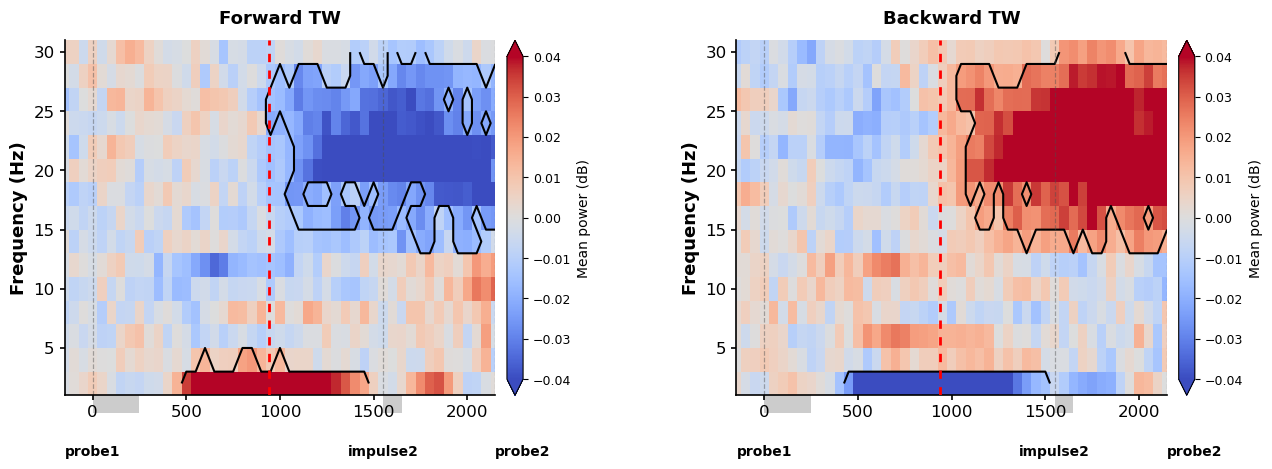

[hand_late | fw | difference]
time=[500.0, 1300.0] ms, freq=[2.0, 2.0] Hz, p=0.0136
time=[300.0, 800.0] ms, freq=[6.0, 14.0] Hz, p=0.0276
time=[950.0, 2000.0] ms, freq=[14.0, 30.0] Hz, p=0.0002
[hand_late | bw | difference]
time=[500.0, 950.0] ms, freq=[4.0, 6.0] Hz, p=0.0408
time=[950.0, 2000.0] ms, freq=[14.0, 30.0] Hz, p=0.0002
time=[450.0, 1350.0] ms, freq=[2.0, 2.0] Hz, p=0.0176
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/mingmin/no-bl/hand_late_fw_bw_tf_difference_4p8-7p1s_zero-5p05s.png


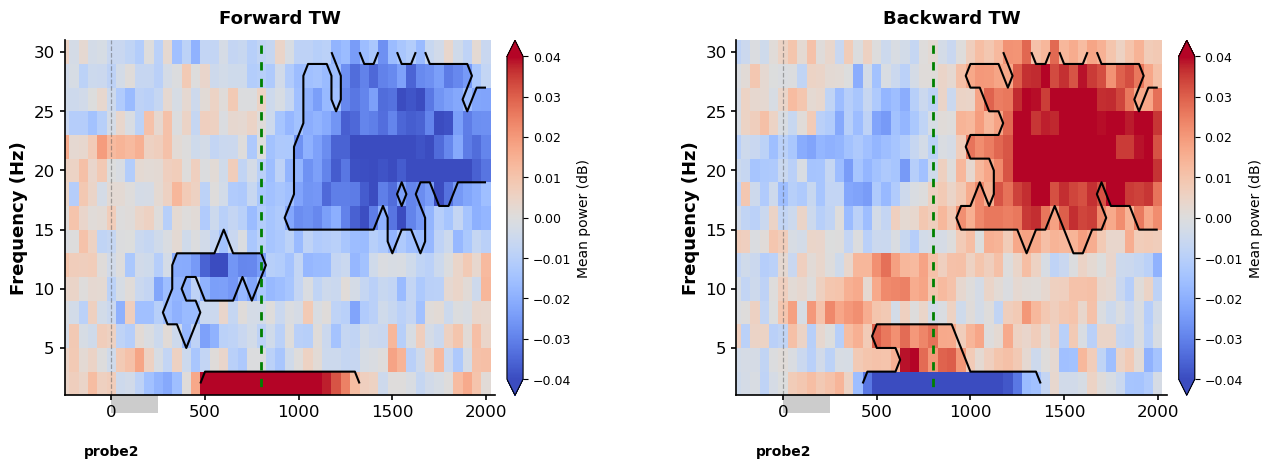

In [25]:
for rt_type in ('early','late'):
    data = prepare_maps(alignment='hand', rt_type=rt_type)['all']
    plots.plot_tf_maps(data, measures=MEASURES, **PLOT_WINDOWS[rt_type],
        limits=TF_LIMITS, diff_limits=TF_DIFF_LIMITS, cmap=TF_CMAP,
        show_sides=TF_SHOW_SIDES, panel_size=TF_PANEL_SIZE, rt_lines=rt_lines(data),
        output_dir=output_dir(), name=f'hand_{rt_type}',
         **PLOT_OPTIONS)


## Response-hand band time courses


[hand_early | fw | theta (2–6 Hz) | all]
time=[550.0, 1400.0] ms, p=0.0002
[hand_early | fw | alpha (8–12 Hz) | all]
time=[450.0, 700.0] ms, p=0.0118
[hand_early | fw | beta (14–30 Hz) | all]
time=[950.0, 2150.0] ms, p=0.0002
[hand_early | bw | theta (2–6 Hz) | all]
time=[750.0, 1150.0] ms, p=0.0084
[hand_early | bw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[650.0, 650.0] ms, p=0.5432
[hand_early | bw | beta (14–30 Hz) | all]
time=[1050.0, 2150.0] ms, p=0.0002
time=[300.0, 650.0] ms, p=0.034
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/mingmin/no-bl/hand_early_fw_bw_bands_2p75-5p05s_zero-2p9s.png


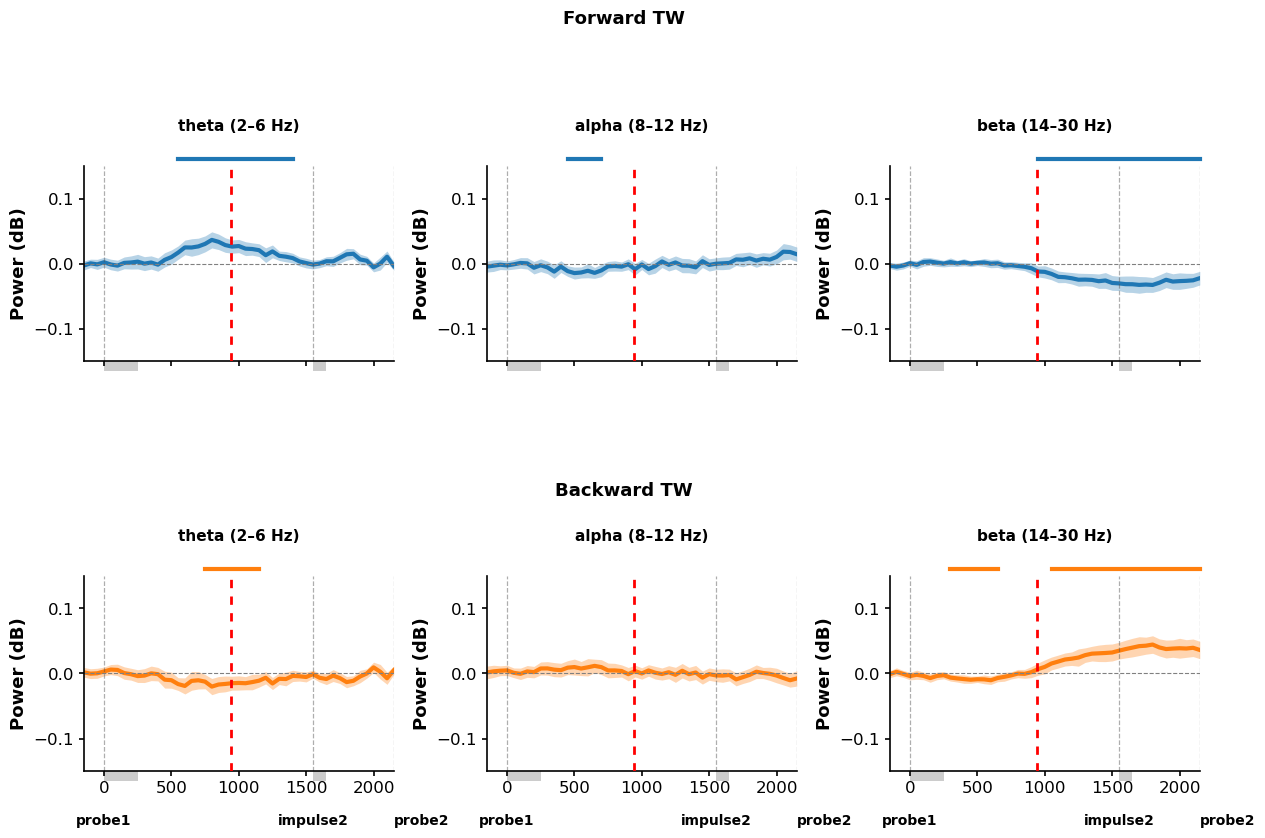

[hand_late | fw | theta (2–6 Hz) | all]
time=[550.0, 1150.0] ms, p=0.0002
[hand_late | fw | alpha (8–12 Hz) | all]
time=[200.0, 800.0] ms, p=0.0008
[hand_late | fw | beta (14–30 Hz) | all]
time=[850.0, 2000.0] ms, p=0.0002
[hand_late | bw | theta (2–6 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[1100.0, 1150.0] ms, p=0.1458
[hand_late | bw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[350.0, 400.0] ms, p=0.1492
[hand_late | bw | beta (14–30 Hz) | all]
time=[950.0, 2000.0] ms, p=0.0002
time=[200.0, 650.0] ms, p=0.0202
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/mingmin/no-bl/hand_late_fw_bw_bands_4p8-7p1s_zero-5p05s.png


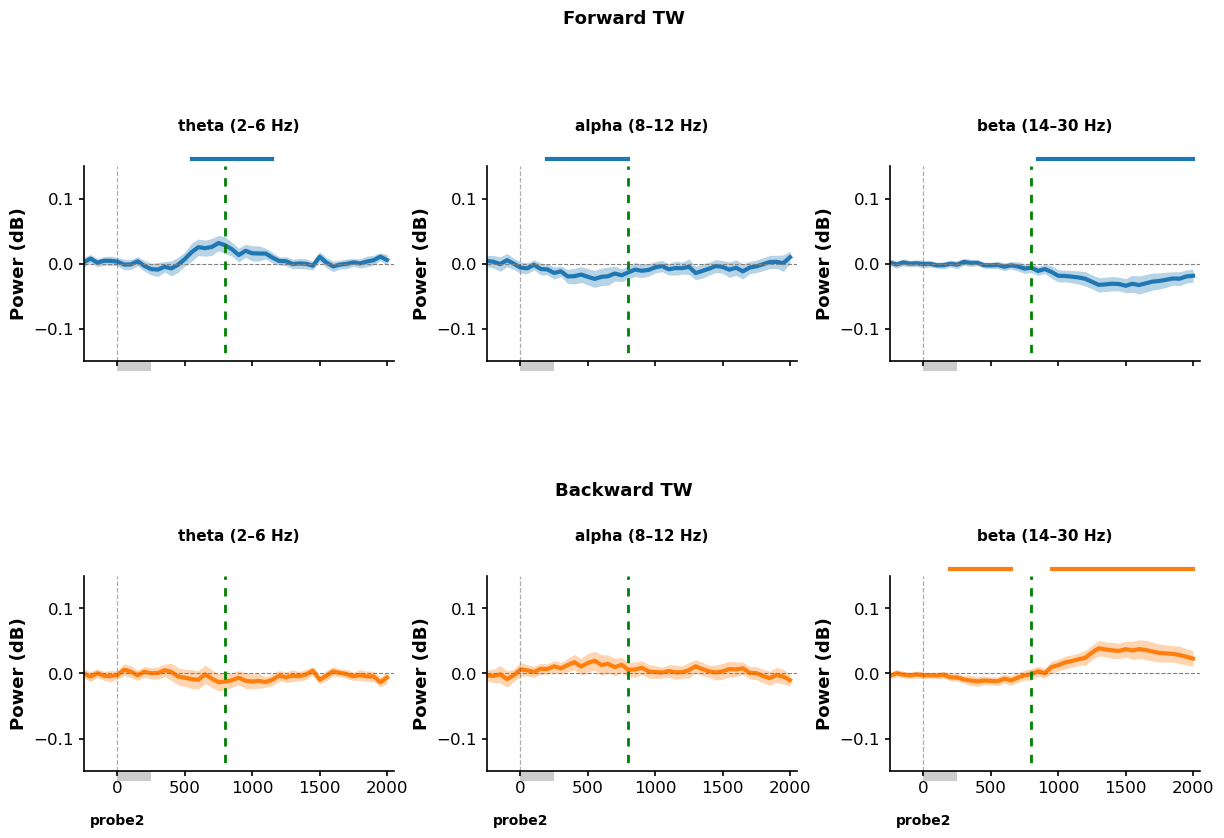

In [26]:
for rt_type in ('early','late'):
    data = prepare_maps(alignment='hand', rt_type=rt_type)['all']
    plots.plot_band_timeseries(data, group='difference', measures=MEASURES,
        freq_bands=FREQ_BANDS, **PLOT_WINDOWS[rt_type], ylims=HAND_YLIMS,
        rt_lines=rt_lines(data), output_dir=output_dir(), name=f'hand_{rt_type}',
         **PLOT_OPTIONS)


## Optional: fast / slow (disabled by default)


In [27]:
RUN_FAST_SLOW = False
if RUN_FAST_SLOW:
    for rt_type in ('early','late'):
        data = prepare_maps(alignment='hand', rt_type=rt_type, comparison='fast_slow')
        lines = [(PROBE_ONSET[rt_type]+np.median(np.concatenate(list(data[key]['rt'][rt_type+'_rt'].values()))), color, key+' RT')
                 for key,color in [('fast','#08306b'),('slow','#a64b00')]]
        plots.plot_band_timeseries(data, group='difference', measures=['fw','bw'],
            freq_bands=FREQ_BANDS, **PLOT_WINDOWS[rt_type], ylims=HAND_YLIMS,
            tests=[('fast',None),('slow',None),('fast','slow')], bands_as_rows=True,
            rt_lines=lines, output_dir=output_dir(), name=f'fast_slow_{rt_type}',
             **PLOT_OPTIONS)


## Fixed / random: whole-trial mean across all 11 electrode lines


[fixed_random_full_trial | fw | theta (2–6 Hz) | fixed − random]
No significant clusters. Minimum-p cluster (not significant):
time=[-550.0, -450.0] ms, p=0.3688
[fixed_random_full_trial | fw | alpha (8–12 Hz) | fixed − random]
No significant clusters. Minimum-p cluster (not significant):
time=[4000.0, 4400.0] ms, p=0.0852
[fixed_random_full_trial | fw | beta (14–30 Hz) | fixed − random]
No significant clusters. Minimum-p cluster (not significant):
time=[5000.0, 5000.0] ms, p=0.622
[fixed_random_full_trial | bw | theta (2–6 Hz) | fixed − random]
No significant clusters. Minimum-p cluster (not significant):
time=[-600.0, -500.0] ms, p=0.4044
[fixed_random_full_trial | bw | alpha (8–12 Hz) | fixed − random]
time=[3700.0, 4250.0] ms, p=0.0486
[fixed_random_full_trial | bw | beta (14–30 Hz) | fixed − random]
time=[3300.0, 4100.0] ms, p=0.0078
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/mingmin/no-bl/fixed_random_full_trial_fw_bw_bands_-1p2-7p5s_zero-0s.png


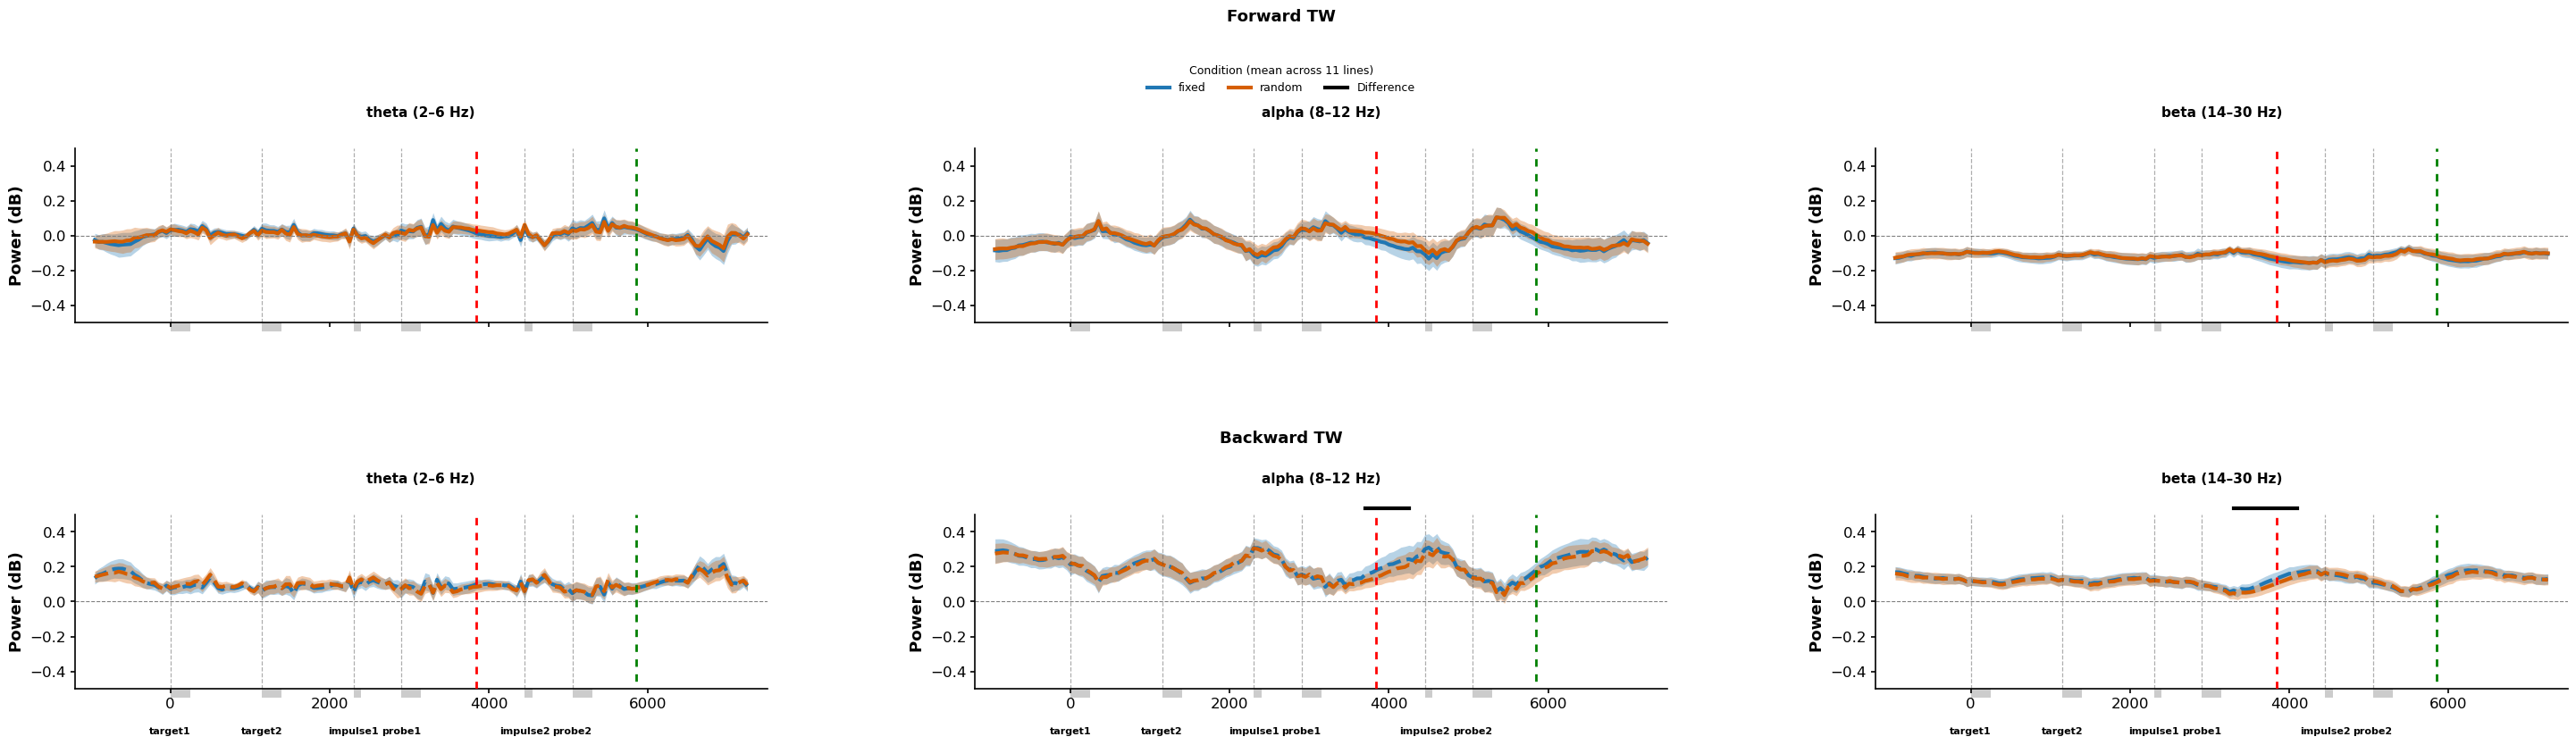

In [28]:
# Average all 11 physical electrode lines (indices 0–10) within each condition.
fixed_random_maps = prepare_maps(
    alignment='physical', comparison='fixed_random',
    groups={'selected': list(range(11))},
)
all_trials = fixed_random_maps.pop('all')
fixed_random_result = plots.plot_band_timeseries(fixed_random_maps, group='selected', measures=MEASURES,
    freq_bands=FREQ_BANDS, **PLOT_WINDOWS['whole'], ylims=POWER_YLIMS,
    tests=[('fixed','random')], split_measures=False,
    measure_linestyles={'fw': '-', 'bw': '--'},
    colors={'fixed':'#1f77b4','random':'#d55e00'},
    legend_title='Condition (mean across 11 lines)',
    rt_lines=rt_lines(all_trials),
    output_dir=output_dir(),
    name='fixed_random_full_trial', event_label_rows=1,
    event_label_fontsize=8, panel_size=(12, 4.2), **PLOT_OPTIONS)
